In [26]:
import pandas as pd

# boxplot version
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../laptop_data_cleaned.csv")

# handle these better with your own dataset, here we are simply dropping these
#df = df.drop(['id', 'date', 'zipcode', 'lat', 'long'], axis=1)

# since price is a continuous variable, it's not practical to use it 
# in some of the visualizations. binning creates a categorical variable
# out of a continuous variable, allowing us the use it in visualizations
# this example bins the price into five categories

# in this dataset, there's some outliers of expensive houses on the high end
# that makes it difficult to compare categories
# this example removes the top 2% houses to make it easier to read the following charts
df = df.query('Price < Price.quantile(q=0.98)')

# for easier visualizations, we'll split the continuous price into categories
df['binned_price'] = pd.cut(df['Price'], bins=5, labels=['Low', 'Below Average', 'Average', 'Above Average', 'High'])

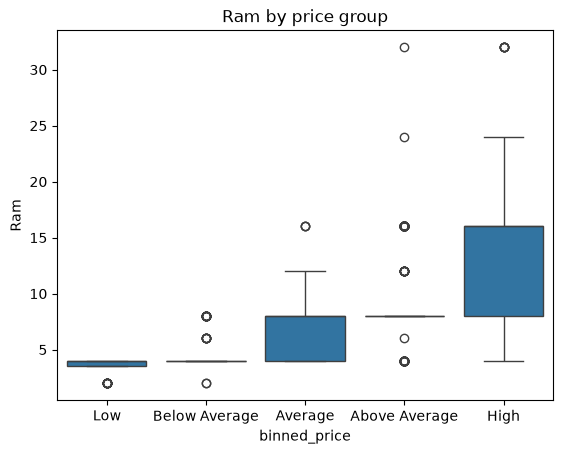

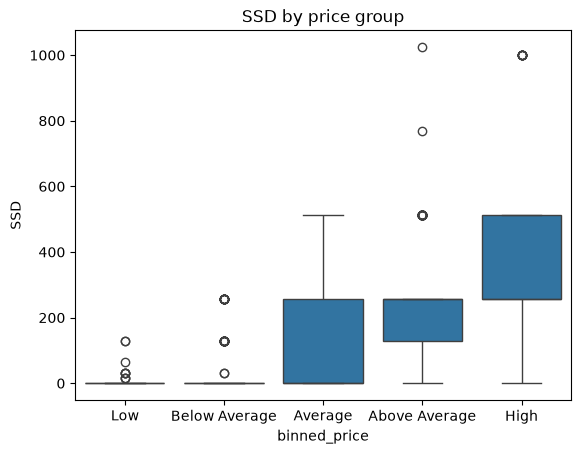

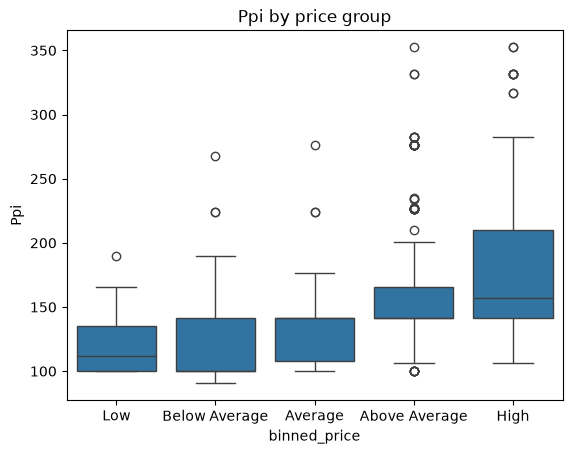

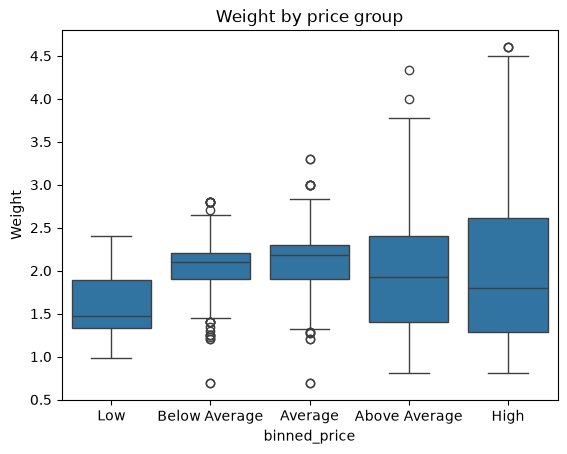

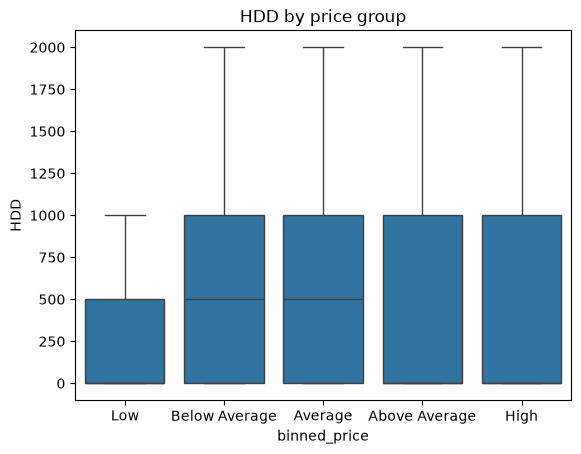

In [27]:
for col in ["Ram", "SSD", "Ppi", "Weight", "HDD"]:
    sns.boxplot(data=df, x="binned_price", y=col)
    plt.title(f"{col} by price group")
    plt.show()

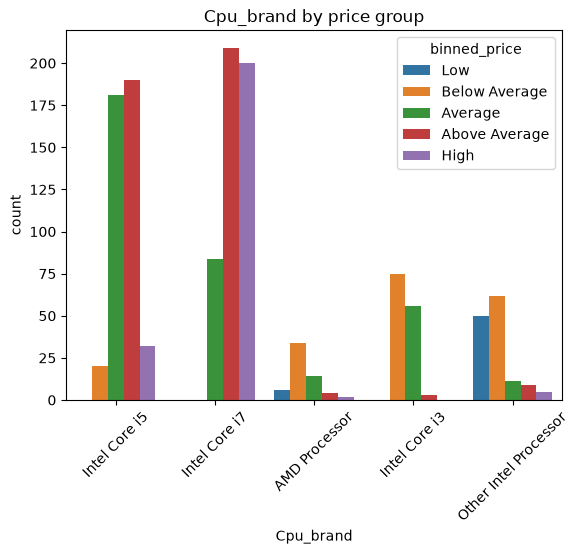

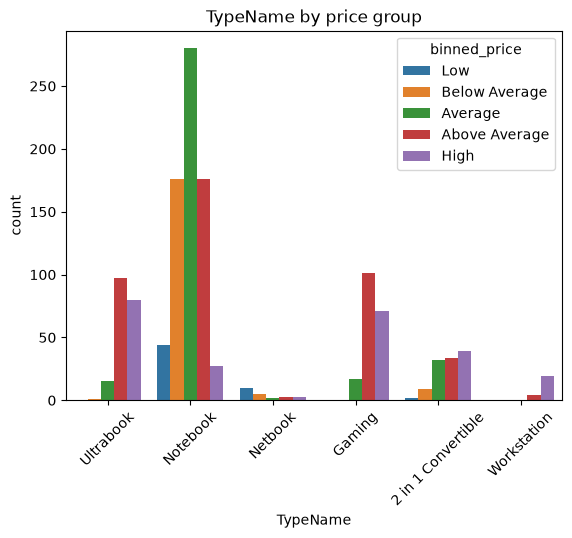

In [28]:
#Count plots for Cpu_brand and TypeName 
for col in ["Cpu_brand", "TypeName"]:
    sns.countplot(data=df, x=col, hue="binned_price")
    plt.xticks(rotation=45)
    plt.title(f"{col} by price group")
    plt.show()

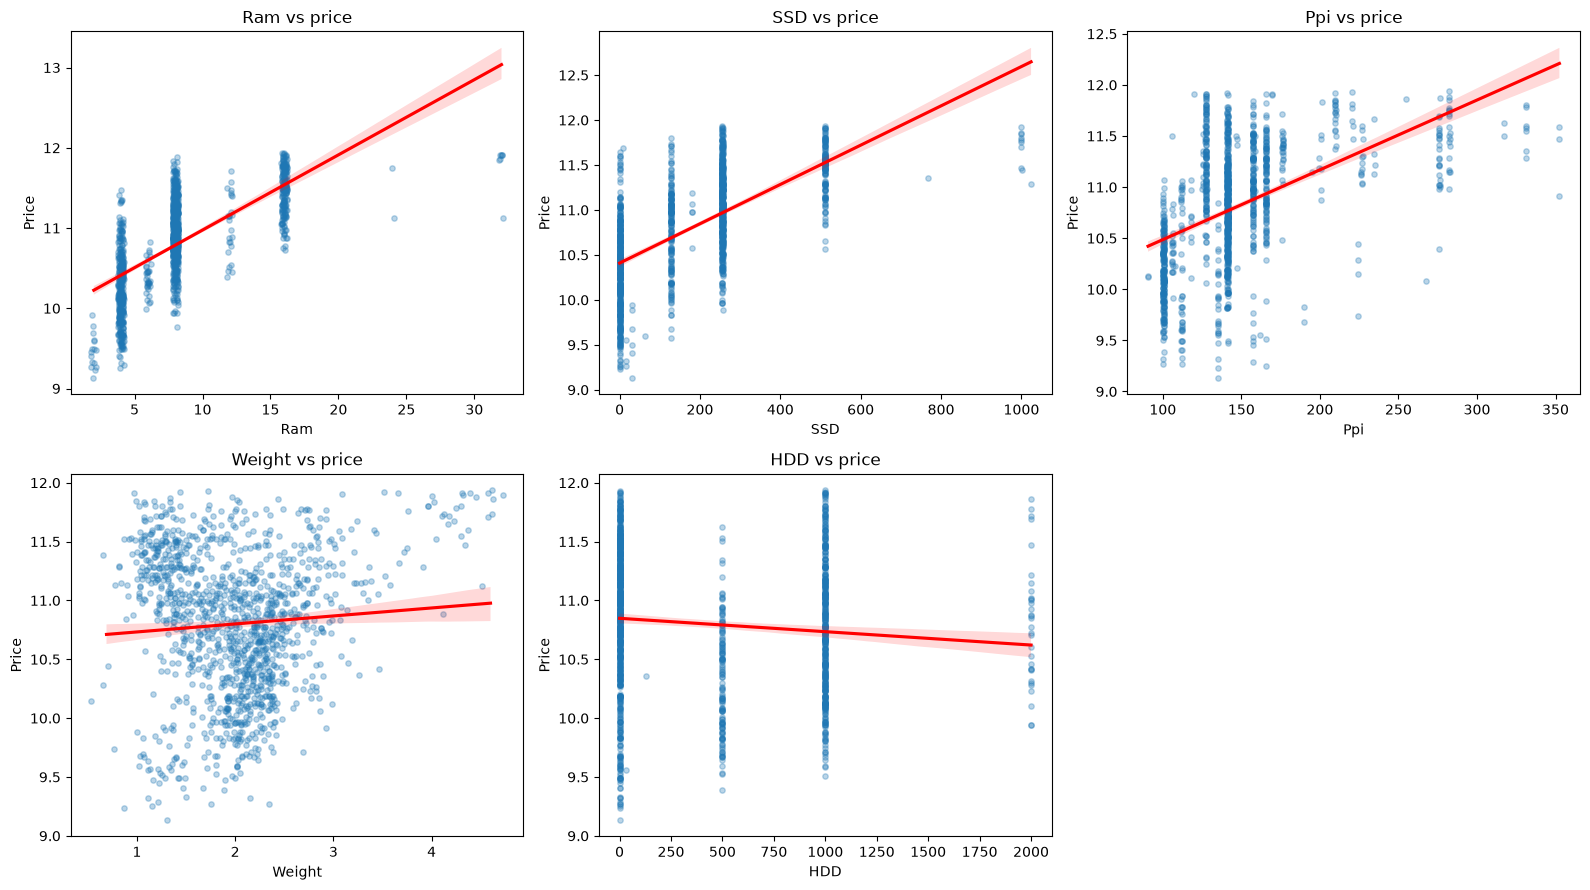

In [29]:
# Numeric features vs Price (scatter and regression plots)
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = ["Ram", "SSD", "Ppi", "Weight", "HDD"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.regplot(data=df, x=col, y="Price", ax=ax,
                x_jitter=0.2, scatter_kws={"alpha": 0.3, "s": 15},
                line_kws={"color": "red"})
    ax.set_title(f"{col} vs price")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

#### Overlap detection with seaborn scatterplots 

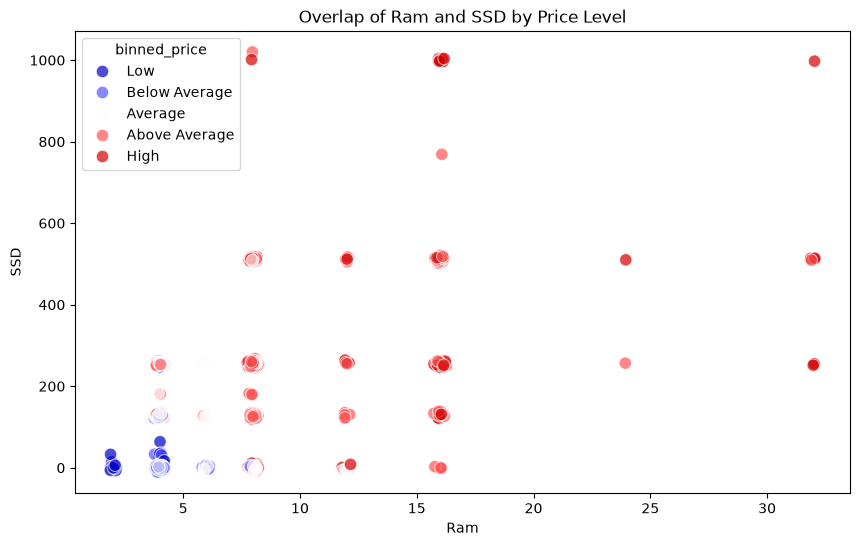

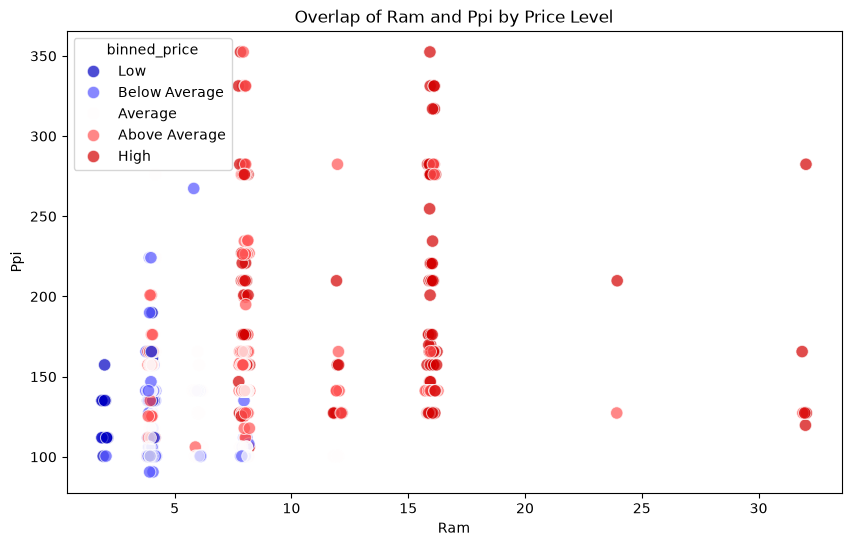

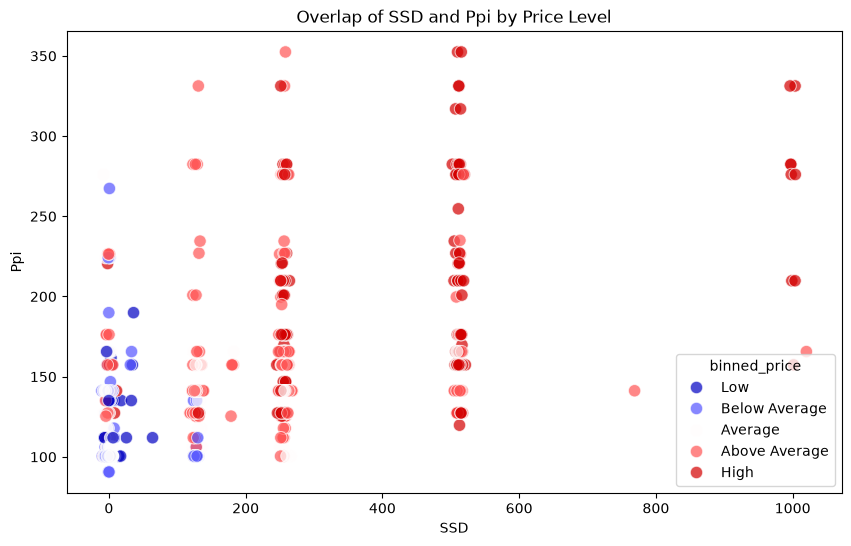

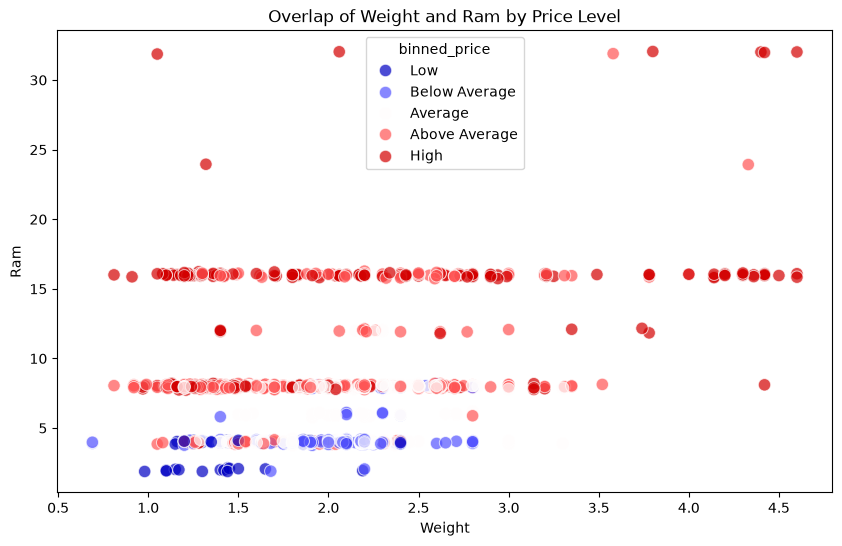

In [30]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Ram and SSD take only a few standard values, so add a little jitter
# to the plotted copy so the points don't hide each other
plot_df = df.copy()
for col in ["Ram", "SSD"]:
    plot_df[col] = plot_df[col] + np.random.normal(0, plot_df[col].std() * 0.02, len(plot_df))

pairs = [("Ram", "SSD"), ("Ram", "Ppi"), ("SSD", "Ppi"), ("Weight", "Ram")]

for x, y in pairs:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=x, y=y, hue="binned_price", data=plot_df,
                    palette="seismic", s=80, alpha=0.7)
    plt.title(f"Overlap of {x} and {y} by Price Level")
    plt.xlabel(x)
    plt.ylabel(y)
    plt.show()

#### Overview of all feature pairs with a pairplot (colored by binned price)

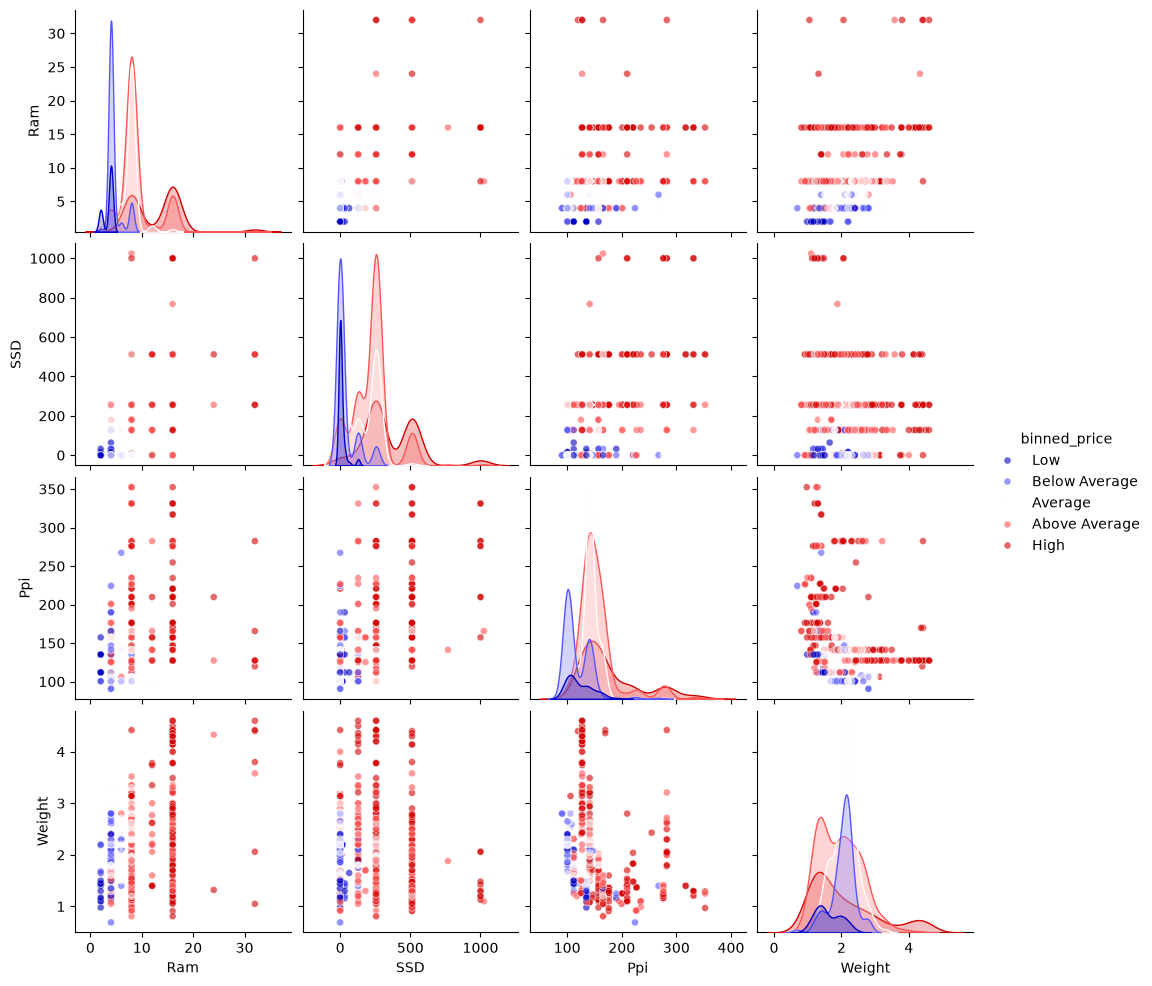

In [31]:
sns.pairplot(df[["Ram", "SSD", "Ppi", "Weight", "binned_price"]],
             hue="binned_price", palette="seismic",
             plot_kws={"alpha": 0.6, "s": 25})
plt.show()